# CMPS 360 - Assignment 1: Hands-on Data Engineering
## Task 1 - Understand the source and define the grain

### Dataset overview

| Item | Description |
|---|---|
| Dataset title | Global AI Jobs 2026 |
| Source organization | Kaggle; dataset published by `datascikhan` |
| Direct URL | [https://www.kaggle.com/datasets/datascikhan/global-ai-jobs-2026](https://www.kaggle.com/datasets/datascikhan/global-ai-jobs-2026) |
| Access date | 2026-10-02 |
| Number of files | 1 |
| File format | CSV (`global_ai_jobs_2026.csv`) |
| Rows and columns | 5,000 rows and 37 columns  |

This dataset is interesting because its topic particularly relevant due to the rapid growth and increasing importance of AI in the global market. The dataset includes attributes such as job role, specialization, locatoin, experience level, salary, required skills, and hiring demand. These attributes enable analysis and comparison of AI employment trends across countries, job types, and experience levels, as well as an examination of how organizational AI investment relates to hiring demand and skill requirements. The dataset also presents relevant data engineering challenges, including multi-valued skill fields, repeated company-level information, and date validation.

### Source grain and key

**The Source Grain:** each row represents one AI Job record with its role, employer, location, specialization, requirements, and hiring attributes.

**Candidate key:** `Job_ID`. It is populated and unique, so it identifies one source row.

### Analytical questions

|  | Question | Columns Used | Type |
|---|---|---|---|
| Q1 | Which 10 companies have the highest total job openings, and how are those openings split across AI specializations? | Company, AI specialization, Job_Openings | Aggregate (SUM), ranking |
| Q2 | Which 10 skills are required most often across job records, and how does their frequency compare across AI specializations? | Skills_Required, AI specialization | Aggregate (COUNT), ranking, comparison |
| Q3 | Which 10 job titles have the highest average salary in USD (among titles with at least 20 records)? | Job title, Salary_USD | Aggregate (AVG), ranking |
| Q4 | How does the average remote-work percentage differ across AI specializations? | AI specialization, Remote_Work_% | Aggregate (AVG), comparison |

*Note: top 10 chosen for readability

### Data dictionary (columns used by the four questions)

| Column | Expected Data Type (Silver) | Unit | Meaning | Used in |
|---|---|---|---|---|
| `Job_ID` | VARCHAR | Identifier | Source record identifier (candidate key) | All |
| `Job_Title` | VARCHAR | Text | Advertised AI-related role | Q3 |
| `AI_Specialization` | VARCHAR | Category | AI area associated with the role | Q1, Q2, Q4 |
| `Company` | VARCHAR | Text | Hiring employer | Q1 |
| `Job_Openings` | INTEGER | Count of openings | Number of vacant positions the employer is trying to fill in this job record | Q1 |
| `Salary_USD` | DECIMAL(12,2) | USD | Salary for the role | Q3 |
| `Remote_Work_%` | INTEGER | Percent, 0 to 100 | Percentage of working time that can be done remotely, from 0 (fully on-site) to 100 (fully remote) | Q4 |
| `Skills_Required` | VARCHAR | Comma-separated skill names | Skills listed for the role; split into one row per skill in Silver | Q2 |

The other 29 columns are not needed for these questions and are not carried into Silver or Gold. Four of them (Salary_Min, Salary_Max, Posted_Date, Record_Created) are read only to check data quality.

## Task 2 - Ingestion strategy

| Decision | Choice | Justification |
|---|---|---|
| Full vs. incremental | **Full first load, then incremental** | The first delivery (`run_date` 2026-10-01, 3,000 rows) is a full load into Bronze. The next two deliveries (1,000 rows each) add only new rows. The Kaggle file is static (update frequency stated as "Never"), so the daily deliveries are simulated by splitting it. |
| Batch vs. streaming | **Batch** | Each delivery is a file processed as a whole, once per `run_date`. The questions do not need real-time results. |
| Push vs. pull | **Pull** | The source does not send data to us. The notebook reads the CSV itself and writes each delivery to `landing_zone/`, so we control when it runs and can re-run it. |

**Frequency:** one delivery per day (`run_date`), matching the three simulated deliveries.

**Watermark:** `Job_ID` is the merge key, and `load_id` / `_load_date` record which delivery loaded each row (`bronze.load_log`). `Record_Created` cannot be a source watermark because it has only one value, and `Posted_Date` contains future dates (2026 to 2039, shown in the notebook). `Posted_Date` is therefore used only to split the file into deliveries, not as a real change timestamp.

**Simulating daily deliveries:** the CSV is sorted by `Posted_Date` and split about 60% / 20% / 20% into `run_date` 2026-10-01 (3,000 rows), 2026-10-02 (1,000) and 2026-10-03 (1,000). The first is the full load; the other two are incremental loads, each with its own `load_id`.

**Rerun and recovery:**
- Raw files stay unchanged in Bronze, so any layer can be rebuilt from them.
- Each load records `load_id`, source file, `ingested_at`, and input row count.
- Silver upserts on `Job_ID`, so re-running a delivery does not create duplicates.
- If a load fails, that delivery is deleted by `run_date` and re-run; completed deliveries are untouched.
- Row counts are compared at each layer (Bronze, Silver valid + quarantined) to confirm nothing was lost.

## Task 3 - Build the Bronze Layer
#### Setup - attach the lakehouse and create the schemas 


In [1]:
import os, shutil
from pathlib import Path

import duckdb
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Image

pd.set_option("display.width", 160); pd.set_option("display.max_columns", 40)

SOURCE_FILE = Path("global_ai_jobs_2026.csv")
LANDING = Path("landing_zone/ai_jobs")         
LAKE_DIR = Path("lakehouse")
USE_DUCKLAKE = True
SOURCE_NAME = "Kaggle - Global AI Jobs 2026"
RUN_DATES = ["2026-10-01", "2026-10-02", "2026-10-03"]   

for folder in ["lakehouse", "landing_zone"]:    
    shutil.rmtree(folder, ignore_errors=True)
for folder in [LAKE_DIR, LANDING, Path("docs")]:
    folder.mkdir(parents=True, exist_ok=True)

con = duckdb.connect()                          
if USE_DUCKLAKE:
    con.execute("INSTALL ducklake; LOAD ducklake;")
    con.execute(f"""ATTACH '{(LAKE_DIR / "ai_jobs_catalog.db").as_posix()}' AS ai_lake
                    (TYPE DUCKLAKE, DATA_PATH '{(LAKE_DIR / "data").as_posix()}/', OVERRIDE_DATA_PATH TRUE)""")
else:
    con.execute(f"ATTACH '{(LAKE_DIR / 'ai_jobs_lakehouse.duckdb').as_posix()}' AS ai_lake")
con.execute("USE ai_lake")
for schema in ["bronze", "silver", "quarantine", "gold"]:
    con.execute(f"CREATE SCHEMA IF NOT EXISTS {schema}")


def sql(query):
    res = con.execute(query)
    try:
        return res.df()
    except Exception:
        return None


print("Backend:", "DuckLake" if USE_DUCKLAKE else "DuckDB file")
sql("SELECT schema_name FROM information_schema.schemata WHERE catalog_name = 'ai_lake' "
    "AND schema_name IN ('bronze','silver','quarantine','gold') ORDER BY 1")

Backend: DuckLake


,schema_name
0,bronze
1,gold
2,quarantine
3,silver


### 3.1. Bronze tables
Bronze keeps the data exactly as received: `read_csv(..., all_varchar = true)` lands every value as text, so dirty values are not hidden. It adds tracking columns:
`source_name`, `load_id`, `_load_date` (the `run_date`), `_ingested_at` and `_source_file`. `bronze.load_log` records the **input row count** of each file next to the rows actually loaded.

In [2]:
sql("""
BEGIN TRANSACTION;

CREATE TABLE IF NOT EXISTS bronze.jobs (
        "Job_ID" VARCHAR,
        "Job_Title" VARCHAR,
        "AI_Specialization" VARCHAR,
        "Industry" VARCHAR,
        "Company" VARCHAR,
        "Company_Size" VARCHAR,
        "Country" VARCHAR,
        "Continent" VARCHAR,
        "Education_Required" VARCHAR,
        "Experience_Level" VARCHAR,
        "Years_of_Experience" VARCHAR,
        "Salary_USD" VARCHAR,
        "Salary_Min" VARCHAR,
        "Salary_Max" VARCHAR,
        "Salary_Category" VARCHAR,
        "Bonus_%" VARCHAR,
        "Equity_Offered" VARCHAR,
        "Benefits_Value_USD" VARCHAR,
        "Skills_Required" VARCHAR,
        "Required_Certifications" VARCHAR,
        "Job_Openings" VARCHAR,
        "Competition_Level_Applicants" VARCHAR,
        "Hiring_Difficulty_1_10" VARCHAR,
        "Job_Type" VARCHAR,
        "Remote_Work_%" VARCHAR,
        "Work_From_Home_Available" VARCHAR,
        "Job_Satisfaction_1_10" VARCHAR,
        "Work_Life_Balance_1_10" VARCHAR,
        "AI_Investment_Company_Millions" VARCHAR,
        "Company_AI_Maturity_1_10" VARCHAR,
        "Job_Growth_Projection_%" VARCHAR,
        "Automation_Risk_%" VARCHAR,
        "Gender_Diversity_%_Female" VARCHAR,
        "Posted_Date" VARCHAR,
        "Application_Deadline" VARCHAR,
        "Record_Created" VARCHAR,
        "Data_Source" VARCHAR,
        source_name   VARCHAR,     -- where the data came from
        load_id       VARCHAR,     -- one id per run_date load
        _load_date    DATE,        -- run_date: which delivery this row belongs to
        _ingested_at  TIMESTAMP,   -- when the notebook wrote the row
        _source_file  VARCHAR      -- file path (lineage)
);

-- One row per loaded file: input row count vs rows actually landed
CREATE TABLE IF NOT EXISTS bronze.load_log (
        load_id           VARCHAR,
        run_date          DATE,
        source_name       VARCHAR,
        source_file       VARCHAR,
        input_row_count   BIGINT,
        loaded_row_count  BIGINT,
        ingested_at       TIMESTAMP,
        status            VARCHAR
);

COMMIT;
""")

,Success


### 3.2 Create the daily extract folders
This simulates three daily deliveries by splitting the source file on `Posted_Date` (about 60% / 20% / 20%, earliest dates first).

In [3]:
src = pd.read_csv(SOURCE_FILE, dtype=str, keep_default_na=False)
ordered = src.sort_values(["Posted_Date", "Job_ID"]).reset_index(drop=True)
cuts = [0, int(len(ordered) * 0.6), int(len(ordered) * 0.8), len(ordered)]
for run_date, a, b in zip(RUN_DATES, cuts[:-1], cuts[1:]):
    folder = LANDING / run_date
    folder.mkdir(parents=True, exist_ok=True)
    part = ordered.iloc[a:b]
    part.to_csv(folder / "global_ai_jobs.csv", index=False)
    print(f"{run_date}: {len(part):>5} rows | Posted_Date {part['Posted_Date'].min()} to {part['Posted_Date'].max()}")
assert sum(len(pd.read_csv(LANDING / d / 'global_ai_jobs.csv')) for d in RUN_DATES) == len(src)

2026-10-01:  3000 rows | Posted_Date 2026-01-01 to 2034-03-19
2026-10-02:  1000 rows | Posted_Date 2034-03-20 to 2036-12-13
2026-10-03:  1000 rows | Posted_Date 2036-12-14 to 2039-09-09


### 3.3 Load one run_date into Bronze
The SQL is stored as a template so the same code loads every day. `DELETE ... WHERE _load_date = run_date` makes a re-run of the same date safe.
We load the first delivery (the **full load**) now.

In [4]:
BRONZE_LOAD = """
BEGIN TRANSACTION;

DELETE FROM bronze.jobs     WHERE _load_date = DATE '{run_date}';
DELETE FROM bronze.load_log WHERE run_date   = DATE '{run_date}';

INSERT INTO bronze.jobs BY NAME
SELECT *,
       '{source_name}'                           AS source_name,
       'load_{run_date_compact}'                 AS load_id,
       DATE '{run_date}'                         AS _load_date,
       current_timestamp                         AS _ingested_at,
       '{extract_file}'                          AS _source_file
FROM read_csv('{extract_file}', header = true, all_varchar = true);

INSERT INTO bronze.load_log
SELECT 'load_{run_date_compact}', DATE '{run_date}', '{source_name}', '{extract_file}',
       (SELECT count(*) FROM read_csv('{extract_file}', header = true, all_varchar = true)),
       (SELECT count(*) FROM bronze.jobs WHERE _load_date = DATE '{run_date}'),
       current_timestamp,
       CASE WHEN (SELECT count(*) FROM read_csv('{extract_file}', header = true, all_varchar = true))
                 = (SELECT count(*) FROM bronze.jobs WHERE _load_date = DATE '{run_date}')
            THEN 'SUCCESS' ELSE 'COUNT_MISMATCH' END;

COMMIT;
"""


def load_bronze(run_date):
    sql(BRONZE_LOAD.format(run_date=run_date, run_date_compact=run_date.replace("-", ""),
                           source_name=SOURCE_NAME,
                           extract_file=(LANDING / run_date / "global_ai_jobs.csv").as_posix()))


run_date = RUN_DATES[0]
load_bronze(run_date)
sql("SELECT * FROM bronze.load_log ORDER BY run_date")

,load_id,run_date,source_name,source_file,input_row_count,loaded_row_count,ingested_at,status
0,load_20261001,2026-10-01,Kaggle - Global AI Jobs 2026,landing_zone/ai_jobs/2026-10-01/global_ai_jobs...,3000,3000,2026-10-10 01:45:00.941325,SUCCESS


Re-running the same `run_date` is safe: the old rows for that date are deleted and loaded again, so the counts do not change.
The tracking columns are visible in the Bronze table.

In [5]:
load_bronze(run_date)                      
display(sql("SELECT * FROM bronze.load_log ORDER BY run_date"))
display(sql("""SELECT "Job_ID", "Job_Title", source_name, load_id, _load_date, _ingested_at, _source_file
               FROM bronze.jobs LIMIT 3"""))
sql("SELECT _load_date, count(*) AS bronze_rows FROM bronze.jobs GROUP BY 1 ORDER BY 1")

,load_id,run_date,source_name,source_file,input_row_count,loaded_row_count,ingested_at,status
0,load_20261001,2026-10-01,Kaggle - Global AI Jobs 2026,landing_zone/ai_jobs/2026-10-01/global_ai_jobs...,3000,3000,2026-10-10 01:45:01.405386,SUCCESS


,Job_ID,Job_Title,source_name,load_id,_load_date,_ingested_at,_source_file
0,AI-00001,AI Ethics Specialist,Kaggle - Global AI Jobs 2026,load_20261001,2026-10-01,2026-10-10 01:45:01.405386,landing_zone/ai_jobs/2026-10-01/global_ai_jobs...
1,AI-00002,AI Project Manager,Kaggle - Global AI Jobs 2026,load_20261001,2026-10-01,2026-10-10 01:45:01.405386,landing_zone/ai_jobs/2026-10-01/global_ai_jobs...
2,AI-00003,Senior Data Scientist,Kaggle - Global AI Jobs 2026,load_20261001,2026-10-01,2026-10-10 01:45:01.405386,landing_zone/ai_jobs/2026-10-01/global_ai_jobs...


,_load_date,bronze_rows
0,2026-10-01,3000


# Task 4 - Build the Silver layer

Silver turns Bronze text into trusted, typed, analysis-ready tables. It only reads the Bronze rows of the current `run_date`
(`WHERE _load_date = run_date`), cleans them in **scratch tables in `memory`** (`memory.stg_*`), and then saves only the good rows with `MERGE INTO`.

| Step | Decision | Why |
|---|---|---|
| Text cleaning | Trim spaces and collapse repeated spaces; blank text becomes NULL; **case is kept** | Prevents the same company or title being counted twice because of spacing. Profiling showed no case-only variants, so changing case was unnecessary. |
| Type casting | `try_cast` to INTEGER, DECIMAL and DATE | A bad value becomes NULL (and fails a rule) instead of crashing the load. |
| Duplicates | `QUALIFY row_number() OVER (PARTITION BY job_id ORDER BY _ingested_at DESC) = 1` | `Job_ID` is the candidate key; the latest copy wins. Removed duplicates are counted in the quality report. |
| Validation | 7 rules (below); failing rows go to `quarantine.jobs` with the reason | Nothing is silently dropped, and every row is accounted for. |
| Skills | Split `Skills_Required` into one row per (job, skill) in `silver.job_skills` | Needed for Q2, because one posting lists several skills. Skills are trimmed and repeats within a job removed. Variants such as `AWS/GCP` and `AWS/GCP/Azure` are kept as written because they may be different requirements. |
| Load | `MERGE INTO` on `job_id` | New keys are inserted, existing keys are updated, so incremental days never duplicate rows. |

**Validation rules**

| Rule | Check |
|---|---|
| R1 | `Job_ID` is present |
| R2 | `Job_Title`, `AI_Specialization` and `Company` are present |
| R3 | `Job_Openings` is a whole number ≥ 0 |
| R4 | `Salary_USD` is numeric and > 0 |
| R5 | `Salary_USD` lies between `Salary_Min` and `Salary_Max` |
| R6 | `Remote_Work_%` is a whole number from 0 to 100 |
| R7 | `Skills_Required` is present |

### 4.1 Silver and quarantine tables

In [6]:
sql("""
BEGIN TRANSACTION;

CREATE TABLE IF NOT EXISTS silver.jobs (
        job_id             VARCHAR,          -- business key (unique)
        job_title          VARCHAR,
        ai_specialization  VARCHAR,
        company            VARCHAR,
        job_openings       INTEGER,          
        salary_usd         DECIMAL(12,2),   
        remote_work_pct    INTEGER,         
        skills_required    VARCHAR,          -- comma-separated; split into silver.job_skills
        _load_date         DATE              -- run_date of the delivery that last wrote this row
);

CREATE TABLE IF NOT EXISTS silver.job_skills (
        job_id  VARCHAR,                     -- FK -> silver.jobs.job_id
        skill   VARCHAR                      -- one row per (job, skill)
);

CREATE TABLE IF NOT EXISTS quarantine.jobs (
        job_id             VARCHAR,
        job_title          VARCHAR,
        ai_specialization  VARCHAR,
        company            VARCHAR,
        job_openings       INTEGER,
        salary_usd         DECIMAL(12,2),
        salary_min         DECIMAL(12,2),
        salary_max         DECIMAL(12,2),
        remote_work_pct    INTEGER,
        skills_required    VARCHAR,
        failed_rules       VARCHAR,          -- rules the row failed, ';'-separated
        _load_date         DATE
);

CREATE TABLE IF NOT EXISTS silver.quality_report (
        run_date  DATE,
        metric    VARCHAR,
        value     BIGINT
);

COMMIT;
""")

,Success


### 4.2 Clean Bronze rows (one output row per input row)

In [7]:
STG_CLEAN = """
CREATE OR REPLACE TABLE memory.stg_jobs_cleaned AS
SELECT
    nullif(regexp_replace(trim("Job_ID"), '\\s+', ' ', 'g'), '')             AS job_id,
    nullif(regexp_replace(trim("Job_Title"), '\\s+', ' ', 'g'), '')          AS job_title,
    nullif(regexp_replace(trim("AI_Specialization"), '\\s+', ' ', 'g'), '')  AS ai_specialization,
    nullif(regexp_replace(trim("Company"), '\\s+', ' ', 'g'), '')            AS company,
    try_cast(trim("Job_Openings") AS INTEGER)                                AS job_openings,
    try_cast(trim("Salary_USD") AS DECIMAL(12,2))                            AS salary_usd,
    try_cast(trim("Salary_Min") AS DECIMAL(12,2))                            AS salary_min,
    try_cast(trim("Salary_Max") AS DECIMAL(12,2))                            AS salary_max,
    try_cast(trim("Remote_Work_%") AS INTEGER)                               AS remote_work_pct,
    nullif(regexp_replace(trim("Skills_Required"), '\\s+', ' ', 'g'), '')    AS skills_required,
    try_cast(trim("Posted_Date") AS DATE)                                    AS posted_date,
    try_cast(trim("Record_Created") AS DATE)                                 AS record_created,
    _ingested_at
FROM bronze.jobs
WHERE _load_date = DATE '{run_date}';
"""
sql(STG_CLEAN.format(run_date=run_date))
sql("SELECT * FROM memory.stg_jobs_cleaned LIMIT 3")

,job_id,job_title,ai_specialization,company,job_openings,salary_usd,salary_min,salary_max,remote_work_pct,skills_required,posted_date,record_created,_ingested_at
0,AI-00001,AI Ethics Specialist,Computer Vision,Databricks,14,103693.0,74921.0,119256.0,40,"Regulatory Compliance, AI Governance, Ethics, ...",2026-01-01,2026-08-28,2026-10-10 01:45:01.405386
1,AI-00002,AI Project Manager,NLP,SenseTime,16,183148.0,152432.0,230735.0,60,"ML/AI Knowledge, Risk Management, Project Mana...",2026-01-02,2026-08-28,2026-10-10 01:45:01.405386
2,AI-00003,Senior Data Scientist,Machine Learning,ByteDance,14,74535.0,63601.0,84396.0,60,"Leadership, Big Data, Statistics, Python, SQL,...",2026-01-03,2026-08-28,2026-10-10 01:45:01.405386


### 4.3 Remove duplicate `Job_ID`s (latest wins) and apply the 7 validation rules

In [8]:
STG_VALIDATE = """
-- Step 3: keep the latest row per job_id
CREATE OR REPLACE TABLE memory.stg_jobs AS
SELECT * FROM memory.stg_jobs_cleaned
QUALIFY row_number() OVER (PARTITION BY job_id ORDER BY _ingested_at DESC) = 1;

-- Step 4: record which rules each row fails (empty string = valid)
CREATE OR REPLACE TABLE memory.stg_jobs_checked AS
SELECT *,
    concat_ws(';',
        CASE WHEN job_id IS NULL THEN 'R1_missing_job_id' END,
        CASE WHEN job_title IS NULL OR ai_specialization IS NULL OR company IS NULL
             THEN 'R2_missing_title_specialization_or_company' END,
        CASE WHEN job_openings IS NULL OR job_openings < 0 THEN 'R3_invalid_job_openings' END,
        CASE WHEN salary_usd IS NULL OR salary_usd <= 0 THEN 'R4_invalid_salary' END,
        CASE WHEN salary_min IS NOT NULL AND salary_max IS NOT NULL
              AND (salary_usd < salary_min OR salary_usd > salary_max) THEN 'R5_salary_outside_min_max' END,
        CASE WHEN remote_work_pct IS NULL OR remote_work_pct NOT BETWEEN 0 AND 100
             THEN 'R6_remote_pct_out_of_range' END,
        CASE WHEN skills_required IS NULL THEN 'R7_missing_skills' END
    ) AS failed_rules
FROM memory.stg_jobs;
"""
sql(STG_VALIDATE)
display(sql("""SELECT (SELECT count(*) FROM memory.stg_jobs_cleaned) AS cleaned_rows,
                      (SELECT count(*) FROM memory.stg_jobs)         AS after_dedup,
                      (SELECT count(*) FROM memory.stg_jobs_checked WHERE failed_rules = '')  AS valid,
                      (SELECT count(*) FROM memory.stg_jobs_checked WHERE failed_rules <> '') AS invalid"""))

,cleaned_rows,after_dedup,valid,invalid
0,3000,3000,3000,0


### 4.4 Save to Silver with `MERGE INTO` and invalid rows to quarantine
One transaction per step. Valid rows are merged into `silver.jobs`, invalid rows into `quarantine.jobs`, and the skills of this day's jobs are replaced in `silver.job_skills`.

In [9]:
SILVER_MERGE = """
BEGIN TRANSACTION;

MERGE INTO silver.jobs AS t
USING (SELECT * FROM memory.stg_jobs_checked WHERE failed_rules = '') AS s
    ON t.job_id = s.job_id
WHEN MATCHED THEN UPDATE SET
    job_title = s.job_title, ai_specialization = s.ai_specialization, company = s.company,
    job_openings = s.job_openings, salary_usd = s.salary_usd, remote_work_pct = s.remote_work_pct,
    skills_required = s.skills_required, _load_date = DATE '{run_date}'
WHEN NOT MATCHED THEN INSERT
    (job_id, job_title, ai_specialization, company, job_openings, salary_usd, remote_work_pct,
     skills_required, _load_date)
VALUES
    (s.job_id, s.job_title, s.ai_specialization, s.company, s.job_openings, s.salary_usd,
     s.remote_work_pct, s.skills_required, DATE '{run_date}');

DELETE FROM quarantine.jobs WHERE _load_date = DATE '{run_date}';
INSERT INTO quarantine.jobs
SELECT job_id, job_title, ai_specialization, company, job_openings, salary_usd, salary_min, salary_max,
       remote_work_pct, skills_required, failed_rules, DATE '{run_date}'
FROM memory.stg_jobs_checked WHERE failed_rules <> '';

DELETE FROM silver.job_skills WHERE job_id IN (SELECT job_id FROM memory.stg_jobs_checked WHERE failed_rules = '');
INSERT INTO silver.job_skills
SELECT DISTINCT job_id, skill FROM (
    SELECT job_id, trim(unnest(string_split(skills_required, ','))) AS skill
    FROM memory.stg_jobs_checked WHERE failed_rules = ''
) WHERE skill <> '';

COMMIT;
"""
sql(SILVER_MERGE.format(run_date=run_date))
sql("""SELECT 'silver.jobs' AS tbl, count(*) AS rows FROM silver.jobs
       UNION ALL SELECT 'silver.job_skills', count(*) FROM silver.job_skills
       UNION ALL SELECT 'quarantine.jobs', count(*) FROM quarantine.jobs""")

,tbl,rows
0,silver.jobs,3000
1,silver.job_skills,17275
2,quarantine.jobs,0


### 4.5 Quality report
For each `run_date` the report stores: Bronze row count, duplicates removed, valid Silver rows, quarantined rows, key uniqueness, null counts for the critical columns (checked before the validation rules, after cleaning), and the date check.

In [10]:
QUALITY = """
DELETE FROM silver.quality_report WHERE run_date = DATE '{run_date}';
INSERT INTO silver.quality_report
WITH c AS (SELECT * FROM memory.stg_jobs_cleaned),
     k AS (SELECT * FROM memory.stg_jobs_checked)
SELECT DATE '{run_date}', metric, value FROM (
          SELECT 'bronze_row_count' AS metric, (SELECT count(*) FROM bronze.jobs WHERE _load_date = DATE '{run_date}') AS value
UNION ALL SELECT 'duplicate_job_id_rows_removed', (SELECT count(*) FROM c) - (SELECT count(*) FROM k)
UNION ALL SELECT 'silver_valid_row_count', count(*) FROM k WHERE failed_rules = ''
UNION ALL SELECT 'quarantined_row_count', count(*) FROM k WHERE failed_rules <> ''
UNION ALL SELECT 'job_id_unique_in_batch (1=yes)', CASE WHEN count(*) = count(DISTINCT job_id) THEN 1 ELSE 0 END FROM k
UNION ALL SELECT 'nulls_job_id', count(*) FILTER (WHERE job_id IS NULL) FROM c
UNION ALL SELECT 'nulls_job_title', count(*) FILTER (WHERE job_title IS NULL) FROM c
UNION ALL SELECT 'nulls_ai_specialization', count(*) FILTER (WHERE ai_specialization IS NULL) FROM c
UNION ALL SELECT 'nulls_company', count(*) FILTER (WHERE company IS NULL) FROM c
UNION ALL SELECT 'nulls_job_openings', count(*) FILTER (WHERE job_openings IS NULL) FROM c
UNION ALL SELECT 'nulls_salary_usd', count(*) FILTER (WHERE salary_usd IS NULL) FROM c
UNION ALL SELECT 'nulls_remote_work_pct', count(*) FILTER (WHERE remote_work_pct IS NULL) FROM c
UNION ALL SELECT 'nulls_skills_required', count(*) FILTER (WHERE skills_required IS NULL) FROM c
UNION ALL SELECT 'flag_posted_date_after_record_created', count(*) FILTER (WHERE posted_date > record_created) FROM k
);
"""
sql(QUALITY.format(run_date=run_date))
sql("SELECT metric, value FROM silver.quality_report WHERE run_date = DATE '{}' ORDER BY rowid".format(run_date))

,metric,value
0,bronze_row_count,3000
1,duplicate_job_id_rows_removed,0
2,silver_valid_row_count,3000
3,quarantined_row_count,0
4,job_id_unique_in_batch (1=yes),1
5,nulls_job_id,0
6,nulls_job_title,0
7,nulls_ai_specialization,0
8,nulls_company,0
9,nulls_job_openings,0


### 4.6 Run the incremental days
Now the same Bronze -> Silver steps run for the next two `run_date`s. `MERGE INTO` inserts only new `Job_ID`s, so the Silver row count grows by exactly each day's extract.

In [11]:
def run_silver(run_date):
    sql(STG_CLEAN.format(run_date=run_date))
    sql(STG_VALIDATE)
    sql(SILVER_MERGE.format(run_date=run_date))
    sql(QUALITY.format(run_date=run_date))


for run_date in RUN_DATES[1:]:
    load_bronze(run_date)
    run_silver(run_date)
    print(run_date, "-> silver.jobs rows:", sql("SELECT count(*) AS n FROM silver.jobs").iloc[0, 0])

display(sql("SELECT * FROM bronze.load_log ORDER BY run_date"))

2026-10-02 -> silver.jobs rows: 4000
2026-10-03 -> silver.jobs rows: 5000


,load_id,run_date,source_name,source_file,input_row_count,loaded_row_count,ingested_at,status
0,load_20261001,2026-10-01,Kaggle - Global AI Jobs 2026,landing_zone/ai_jobs/2026-10-01/global_ai_jobs...,3000,3000,2026-10-10 01:45:01.405386,SUCCESS
1,load_20261002,2026-10-02,Kaggle - Global AI Jobs 2026,landing_zone/ai_jobs/2026-10-02/global_ai_jobs...,1000,1000,2026-10-10 01:45:02.125083,SUCCESS
2,load_20261003,2026-10-03,Kaggle - Global AI Jobs 2026,landing_zone/ai_jobs/2026-10-03/global_ai_jobs...,1000,1000,2026-10-10 01:45:02.480491,SUCCESS


### Overall quality report (all run dates)

In [12]:
report = sql("""
    SELECT metric, sum(value)::BIGINT AS total_all_runs
    FROM silver.quality_report WHERE metric NOT LIKE 'job_id_unique%' GROUP BY metric ORDER BY min(rowid)""")
display(report)
display(sql("""SELECT count(*) AS silver_rows, count(DISTINCT job_id) AS distinct_job_id,
                      count(*) = count(DISTINCT job_id) AS job_id_is_unique FROM silver.jobs"""))
print("Silver column types:")
display(sql("DESCRIBE silver.jobs")[["column_name", "column_type"]])

,metric,total_all_runs
0,bronze_row_count,5000
1,duplicate_job_id_rows_removed,0
2,silver_valid_row_count,5000
3,quarantined_row_count,0
4,nulls_job_id,0
5,nulls_job_title,0
6,nulls_ai_specialization,0
7,nulls_company,0
8,nulls_job_openings,0
9,nulls_salary_usd,0


,silver_rows,distinct_job_id,job_id_is_unique
0,5000,5000,True


Silver column types:


,column_name,column_type
0,job_id,VARCHAR
1,job_title,VARCHAR
2,ai_specialization,VARCHAR
3,company,VARCHAR
4,job_openings,INTEGER
5,salary_usd,"DECIMAL(12,2)"
6,remote_work_pct,INTEGER
7,skills_required,VARCHAR
8,_load_date,DATE


Bronze (5,000) = Silver valid (5,000) + quarantined (0) + duplicates removed (0). There are no nulls in the critical columns, and Job_ID is unique within every batch and across all of Silver (5,000 rows, 5,000 distinct keys). The source is very clean, so no rows fail any rule. The one data problem found is the date issue: 4,760 rows have `Posted_Date` later than `Record_Created`. It is reported here but not stored in Silver, because dates are not used by the four questions. The seven rules are applied to every row, and any failing row would be written to `quarantine.jobs` with its reason, so an empty quarantine here is a result and not a missing check.


# Task 5 - Design and implement the Gold star schema

The Gold layer is designed around the four questions and nothing more.

- **Fact table `fact_job_posting`.** **Grain: one row per job posting (`Job_ID`).** Measures: `job_openings`, `salary_usd`, `remote_work_pct`.
- **Dimensions (4):** `dim_company` (Q1), `dim_job_title` (Q3), `dim_specialization` (Q1, Q2, Q4), `dim_skill` (Q2).
- **Bridge `bridge_job_skill`.** A posting lists several skills, and a skill appears in many postings (many-to-many). The bridge keeps the fact grain at one row per
  posting, so salary and openings are never double-counted. Only counts are taken across the bridge.
- **Left out on purpose:** industry, country, experience, certifications and dates, because none of the four questions needs them.

| Table | Primary key | Foreign keys |
|---|---|---|
| `fact_job_posting` | `job_id` | `company_key`, `title_key`, `specialization_key` |
| `dim_company` | `company_key` | none |
| `dim_job_title` | `title_key` | none |
| `dim_specialization` | `specialization_key` | none |
| `dim_skill` | `skill_key` | none |
| `bridge_job_skill` | (`job_id`, `skill_key`) | `job_id` → fact, `skill_key` → `dim_skill` |

**Loading with `MERGE INTO`.** Each dimension inserts only values it does not have yet, and new surrogate keys continue after the current maximum, so **existing keys never change** between runs.
The fact table is merged on `job_id`: new postings are inserted and existing ones updated. 

### 5.1 Gold tables (star schema)

In [13]:
sql("""
BEGIN TRANSACTION;

CREATE TABLE IF NOT EXISTS gold.dim_company        (company_key INTEGER,        company_name VARCHAR);        -- PK company_key
CREATE TABLE IF NOT EXISTS gold.dim_job_title      (title_key INTEGER,          job_title VARCHAR);           -- PK title_key
CREATE TABLE IF NOT EXISTS gold.dim_specialization (specialization_key INTEGER, specialization_name VARCHAR); -- PK specialization_key
CREATE TABLE IF NOT EXISTS gold.dim_skill          (skill_key INTEGER,          skill_name VARCHAR);          -- PK skill_key

-- Fact grain: one row per job posting
CREATE TABLE IF NOT EXISTS gold.fact_job_posting (
        job_id              VARCHAR,         -- PK
        company_key         INTEGER,         -- FK -> dim_company
        title_key           INTEGER,         -- FK -> dim_job_title
        specialization_key  INTEGER,         -- FK -> dim_specialization
        job_openings        INTEGER,         -- measure
        salary_usd          DECIMAL(12,2),   -- measure
        remote_work_pct     INTEGER          -- measure
);

-- Many-to-many: a posting lists several skills
CREATE TABLE IF NOT EXISTS gold.bridge_job_skill (
        job_id     VARCHAR,                  -- FK -> fact_job_posting
        skill_key  INTEGER                   -- FK -> dim_skill
);

COMMIT;
""")
sql("""SELECT table_schema AS layer, table_name, count(*) AS columns
       FROM information_schema.columns
       WHERE table_catalog = 'ai_lake' AND table_schema IN ('bronze','silver','quarantine','gold')
       GROUP BY ALL ORDER BY 1, 2""")

,layer,table_name,columns
0,bronze,jobs,42
1,bronze,load_log,8
2,gold,bridge_job_skill,2
3,gold,dim_company,2
4,gold,dim_job_title,2
5,gold,dim_skill,2
6,gold,dim_specialization,2
7,gold,fact_job_posting,7
8,quarantine,jobs,12
9,silver,job_skills,2


In [14]:
GOLD_LOAD = """
BEGIN TRANSACTION;

-- Dimensions
MERGE INTO gold.dim_company AS t
USING (SELECT company AS name, (SELECT coalesce(max(company_key), 0) FROM gold.dim_company)
              + row_number() OVER (ORDER BY company) AS new_key
       FROM (SELECT DISTINCT company FROM silver.jobs)) AS s
    ON t.company_name = s.name
WHEN NOT MATCHED THEN INSERT (company_key, company_name) VALUES (s.new_key, s.name);

MERGE INTO gold.dim_job_title AS t
USING (SELECT job_title AS name, (SELECT coalesce(max(title_key), 0) FROM gold.dim_job_title)
              + row_number() OVER (ORDER BY job_title) AS new_key
       FROM (SELECT DISTINCT job_title FROM silver.jobs)) AS s
    ON t.job_title = s.name
WHEN NOT MATCHED THEN INSERT (title_key, job_title) VALUES (s.new_key, s.name);

MERGE INTO gold.dim_specialization AS t
USING (SELECT ai_specialization AS name, (SELECT coalesce(max(specialization_key), 0) FROM gold.dim_specialization)
              + row_number() OVER (ORDER BY ai_specialization) AS new_key
       FROM (SELECT DISTINCT ai_specialization FROM silver.jobs)) AS s
    ON t.specialization_name = s.name
WHEN NOT MATCHED THEN INSERT (specialization_key, specialization_name) VALUES (s.new_key, s.name);

MERGE INTO gold.dim_skill AS t
USING (SELECT skill AS name, (SELECT coalesce(max(skill_key), 0) FROM gold.dim_skill)
              + row_number() OVER (ORDER BY skill) AS new_key
       FROM (SELECT DISTINCT skill FROM silver.job_skills)) AS s
    ON t.skill_name = s.name
WHEN NOT MATCHED THEN INSERT (skill_key, skill_name) VALUES (s.new_key, s.name);

-- Fact: one row per job posting
MERGE INTO gold.fact_job_posting AS t
USING (SELECT j.job_id, c.company_key, ti.title_key, sp.specialization_key,
              j.job_openings, j.salary_usd, j.remote_work_pct
       FROM silver.jobs j
       JOIN gold.dim_company        c  ON c.company_name        = j.company
       JOIN gold.dim_job_title      ti ON ti.job_title          = j.job_title
       JOIN gold.dim_specialization sp ON sp.specialization_name = j.ai_specialization
       WHERE j._load_date = DATE '{run_date}') AS s
    ON t.job_id = s.job_id
WHEN MATCHED THEN UPDATE SET
    company_key = s.company_key, title_key = s.title_key, specialization_key = s.specialization_key,
    job_openings = s.job_openings, salary_usd = s.salary_usd, remote_work_pct = s.remote_work_pct
WHEN NOT MATCHED THEN INSERT
    (job_id, company_key, title_key, specialization_key, job_openings, salary_usd, remote_work_pct)
VALUES
    (s.job_id, s.company_key, s.title_key, s.specialization_key, s.job_openings, s.salary_usd, s.remote_work_pct);

-- Bridge: replace the skills of this day's postings
DELETE FROM gold.bridge_job_skill
WHERE job_id IN (SELECT job_id FROM silver.jobs WHERE _load_date = DATE '{run_date}');
INSERT INTO gold.bridge_job_skill
SELECT js.job_id, k.skill_key
FROM silver.job_skills js
JOIN silver.jobs j ON j.job_id = js.job_id AND j._load_date = DATE '{run_date}'
JOIN gold.dim_skill k ON k.skill_name = js.skill;

COMMIT;
"""

GOLD_CHECKS = """
SELECT 'fact rows = silver rows' AS check_name,
       (SELECT count(*) FROM gold.fact_job_posting) AS value, (SELECT count(*) FROM silver.jobs) AS expected
UNION ALL SELECT 'fact job_id unique (distinct)', count(DISTINCT job_id), count(*) FROM gold.fact_job_posting
UNION ALL SELECT 'dim_company key unique', count(DISTINCT company_key), count(*) FROM gold.dim_company
UNION ALL SELECT 'dim_skill key unique', count(DISTINCT skill_key), count(*) FROM gold.dim_skill
UNION ALL SELECT 'orphan company_key', count(*), 0 FROM gold.fact_job_posting f
          WHERE NOT EXISTS (SELECT 1 FROM gold.dim_company d WHERE d.company_key = f.company_key)
UNION ALL SELECT 'orphan title_key', count(*), 0 FROM gold.fact_job_posting f
          WHERE NOT EXISTS (SELECT 1 FROM gold.dim_job_title d WHERE d.title_key = f.title_key)
UNION ALL SELECT 'orphan specialization_key', count(*), 0 FROM gold.fact_job_posting f
          WHERE NOT EXISTS (SELECT 1 FROM gold.dim_specialization d WHERE d.specialization_key = f.specialization_key)
UNION ALL SELECT 'bridge orphan job_id', count(*), 0 FROM gold.bridge_job_skill b
          WHERE NOT EXISTS (SELECT 1 FROM gold.fact_job_posting f WHERE f.job_id = b.job_id)
UNION ALL SELECT 'bridge orphan skill_key', count(*), 0 FROM gold.bridge_job_skill b
          WHERE NOT EXISTS (SELECT 1 FROM gold.dim_skill d WHERE d.skill_key = b.skill_key)
"""

for run_date in RUN_DATES:
    sql(GOLD_LOAD.format(run_date=run_date))
    print(run_date, "-> fact rows:", sql("SELECT count(*) AS n FROM gold.fact_job_posting").iloc[0, 0])

gold_checks = sql(GOLD_CHECKS)
gold_checks["passed"] = gold_checks["value"] == gold_checks["expected"]
display(gold_checks)
assert gold_checks["passed"].all(), "Gold integrity check failed"

2026-10-01 -> fact rows: 3000
2026-10-02 -> fact rows: 4000
2026-10-03 -> fact rows: 5000


,check_name,value,expected,passed
0,fact rows = silver rows,5000,5000,True
1,fact job_id unique (distinct),5000,5000,True
2,dim_company key unique,60,60,True
3,dim_skill key unique,102,102,True
4,orphan company_key,0,0,True
5,orphan title_key,0,0,True
6,orphan specialization_key,0,0,True
7,bridge orphan job_id,0,0,True
8,bridge orphan skill_key,0,0,True


**Idempotency check.** Running the Gold load again for a `run_date` must not change any count, because the dimensions only insert missing values and the fact table is merged on `job_id`.

In [15]:
def gold_counts():
    return {t: int(sql(f"SELECT count(*) AS n FROM gold.{t}").iloc[0, 0])
            for t in ["fact_job_posting", "dim_company", "dim_job_title", "dim_specialization", "dim_skill", "bridge_job_skill"]}

before = gold_counts()
sql(GOLD_LOAD.format(run_date=RUN_DATES[-1]))          # re-run the last day
after = gold_counts()
print("before:", before); print("after :", after); print("unchanged:", before == after)
assert before == after

before: {'fact_job_posting': 5000, 'dim_company': 60, 'dim_job_title': 36, 'dim_specialization': 8, 'dim_skill': 102, 'bridge_job_skill': 28804}
after : {'fact_job_posting': 5000, 'dim_company': 60, 'dim_job_title': 36, 'dim_specialization': 8, 'dim_skill': 102, 'bridge_job_skill': 28804}
unchanged: True


### Star-schema diagram

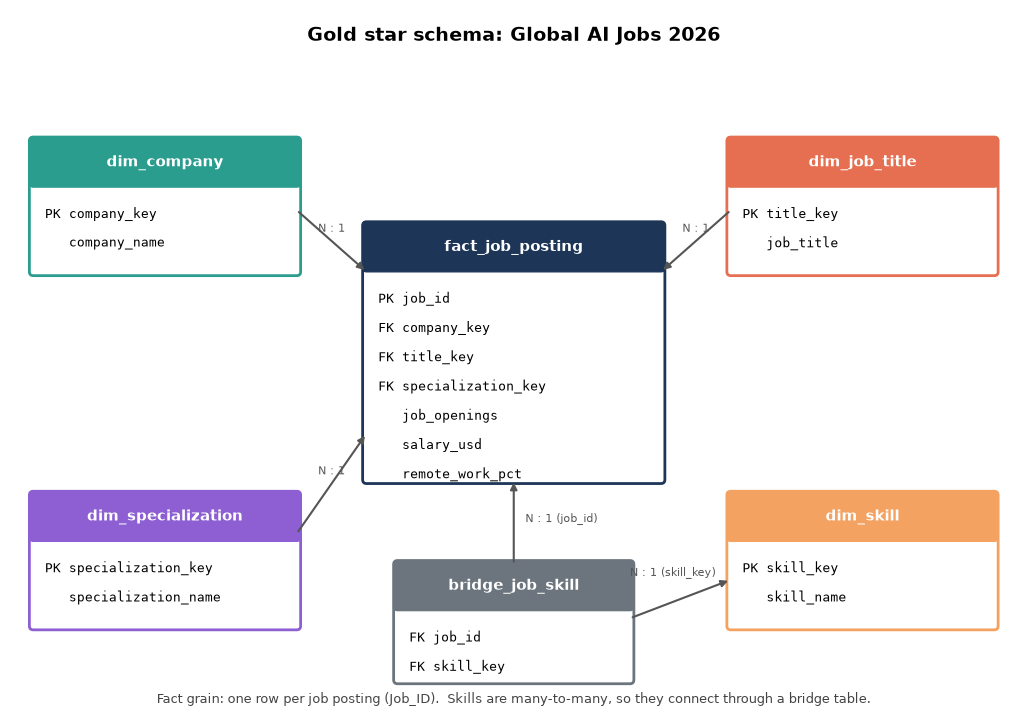

,column_name,column_type
0,job_id,VARCHAR
1,company_key,INTEGER
2,title_key,INTEGER
3,specialization_key,INTEGER
4,job_openings,INTEGER
5,salary_usd,"DECIMAL(12,2)"
6,remote_work_pct,INTEGER


In [16]:
from matplotlib.patches import FancyBboxPatch

fig, ax = plt.subplots(figsize=(13, 9))
ax.set_xlim(0, 13); ax.set_ylim(0, 9); ax.axis("off")


def box(x, y, w, h, title, lines, color):
    ax.add_patch(FancyBboxPatch((x, y), w, h, boxstyle="round,pad=0.05", fc="white", ec=color, lw=2))
    ax.add_patch(FancyBboxPatch((x, y + h - 0.55), w, 0.55, boxstyle="round,pad=0.05", fc=color, ec=color))
    ax.text(x + w / 2, y + h - 0.28, title, ha="center", va="center", color="white", fontsize=11, fontweight="bold")
    for i, line in enumerate(lines):
        ax.text(x + 0.15, y + h - 0.95 - i * 0.38, line, fontsize=9, va="center", family="monospace")


def link(x1, y1, x2, y2, label="", lx=None, ly=None):
    ax.annotate("", xy=(x2, y2), xytext=(x1, y1), arrowprops=dict(arrowstyle="-|>", color="#555", lw=1.5))
    if label:
        ax.text(lx if lx is not None else (x1 + x2) / 2, ly if ly is not None else (y1 + y2) / 2 + 0.12,
                label, fontsize=8, color="#555", ha="center")


box(4.6, 2.9, 3.8, 3.3, "fact_job_posting", ["PK job_id", "FK company_key", "FK title_key", "FK specialization_key",
                                              "   job_openings", "   salary_usd", "   remote_work_pct"], "#1d3557")
box(0.3, 5.6, 3.4, 1.7, "dim_company", ["PK company_key", "   company_name"], "#2a9d8f")
box(9.3, 5.6, 3.4, 1.7, "dim_job_title", ["PK title_key", "   job_title"], "#e76f51")
box(0.3, 1.0, 3.4, 1.7, "dim_specialization", ["PK specialization_key", "   specialization_name"], "#8d5fd3")
box(9.3, 1.0, 3.4, 1.7, "dim_skill", ["PK skill_key", "   skill_name"], "#f4a261")
box(5.0, 0.3, 3.0, 1.5, "bridge_job_skill", ["FK job_id", "FK skill_key"], "#6c757d")
link(3.7, 6.4, 4.6, 5.6, "N : 1")
link(9.3, 6.4, 8.4, 5.6, "N : 1")
link(3.7, 2.2, 4.6, 3.5, "N : 1")
link(6.5, 1.8, 6.5, 2.9); ax.text(6.65, 2.35, "N : 1 (job_id)", fontsize=8, color="#555")
link(8.0, 1.1, 9.3, 1.6); ax.text(8.0, 1.65, "N : 1 (skill_key)", fontsize=8, color="#555")
ax.text(6.5, 8.6, "Gold star schema: Global AI Jobs 2026", ha="center", fontsize=14, fontweight="bold")
ax.text(6.5, 0.0, "Fact grain: one row per job posting (Job_ID).  Skills are many-to-many, so they connect through a bridge table.",
        ha="center", fontsize=9, color="#444")
plt.savefig("docs/star_schema.png", dpi=150, bbox_inches="tight")
plt.show()
display(sql("DESCRIBE gold.fact_job_posting")[["column_name", "column_type"]])

# Task 6 - Answer the four questions 
## Q1. Which 10 companies have the highest total job openings, and how are those openings split across AI specializations?

In [17]:
Q1 = """
WITH top_companies AS (
    SELECT c.company_key, c.company_name, SUM(f.job_openings) AS total_openings
    FROM gold.fact_job_posting f JOIN gold.dim_company c USING (company_key)
    GROUP BY c.company_key, c.company_name
    ORDER BY total_openings DESC, c.company_name
    LIMIT 10)
SELECT t.company_name, t.total_openings, s.specialization_name, SUM(f.job_openings) AS openings
FROM top_companies t
JOIN gold.fact_job_posting f USING (company_key)
JOIN gold.dim_specialization s USING (specialization_key)
GROUP BY t.company_name, t.total_openings, s.specialization_name
ORDER BY t.total_openings DESC, t.company_name, openings DESC"""
r1 = sql(Q1)
display(r1.drop_duplicates("company_name")[["company_name", "total_openings"]].reset_index(drop=True))
display(r1.head(16))

,company_name,total_openings
0,Alibaba,1063.0
1,Lyft,1059.0
2,Microsoft,996.0
3,Hitachi,992.0
4,Salesforce,983.0
5,KPMG,981.0
6,IBM,953.0
7,Snowflake,951.0
8,OpenAI,944.0
9,LinkedIn,939.0


,company_name,total_openings,specialization_name,openings
0,Alibaba,1063.0,Robotics,192.0
1,Alibaba,1063.0,Reinforcement Learning,167.0
2,Alibaba,1063.0,Machine Learning,138.0
3,Alibaba,1063.0,Generative AI,133.0
4,Alibaba,1063.0,Other,131.0
5,Alibaba,1063.0,NLP,115.0
6,Alibaba,1063.0,Computer Vision,97.0
7,Alibaba,1063.0,Deep Learning,90.0
8,Lyft,1059.0,Robotics,173.0
9,Lyft,1059.0,Reinforcement Learning,163.0


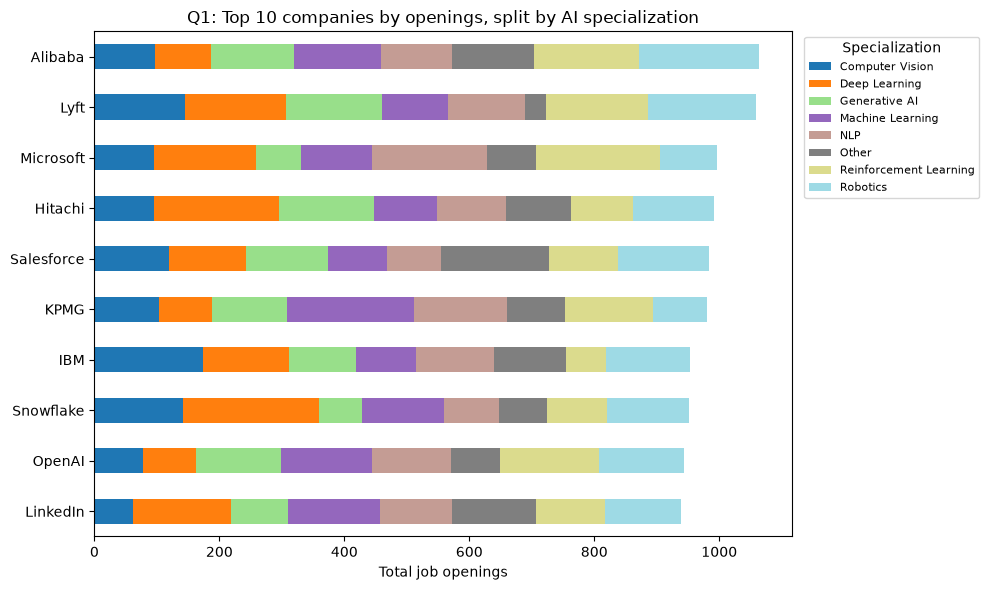

In [18]:
d = r1.pivot_table(index="company_name", columns="specialization_name", values="openings", aggfunc="sum", fill_value=0)
d = d.loc[d.sum(axis=1).sort_values().index]
ax = d.plot(kind="barh", stacked=True, figsize=(10, 6), colormap="tab20")
ax.set_xlabel("Total job openings"); ax.set_ylabel("")
ax.set_title("Q1: Top 10 companies by openings, split by AI specialization")
ax.legend(title="Specialization", bbox_to_anchor=(1.01, 1), loc="upper left", fontsize=8)
plt.tight_layout()
plt.show()

**Interpretation (Q1).** Alibaba has the most openings (1,063), narrowly ahead of Lyft (1,059), then Microsoft (996) and Hitachi (992).
The ten companies lie between 939 and 1,063 openings, a narrow band, and together hold 9,861 of the 50,368 openings in the data (about 20%).
So hiring demand is spread across many employers (60 in total) rather than concentrated in a few. Within each company no single specialization dominates:
Alibaba's largest share is Robotics (192 of 1,063, about 18%), and Lyft's is also Robotics (173), so openings are spread over all eight specializations.

## Q2. Which 10 skills are required most often across job records, and how does their frequency compare across AI specializations?

In [19]:
Q2 = """
WITH top_skills AS (
    SELECT k.skill_key, k.skill_name, COUNT(*) AS total_postings
    FROM gold.bridge_job_skill b JOIN gold.dim_skill k USING (skill_key)
    GROUP BY k.skill_key, k.skill_name
    ORDER BY total_postings DESC, k.skill_name
    LIMIT 10)
SELECT ts.skill_name, ts.total_postings, s.specialization_name, COUNT(*) AS postings_in_specialization
FROM top_skills ts
JOIN gold.bridge_job_skill b USING (skill_key)
JOIN gold.fact_job_posting f USING (job_id)
JOIN gold.dim_specialization s USING (specialization_key)
GROUP BY ts.skill_name, ts.total_postings, s.specialization_name
ORDER BY ts.total_postings DESC, ts.skill_name, postings_in_specialization DESC"""
r2 = sql(Q2)
display(r2.drop_duplicates("skill_name")[["skill_name", "total_postings"]].reset_index(drop=True))
display(r2.pivot_table(index="skill_name", columns="specialization_name", values="postings_in_specialization")
          .loc[r2.drop_duplicates("skill_name")["skill_name"]])

,skill_name,total_postings
0,Python,4008
1,PyTorch,1396
2,SQL,981
3,Research,868
4,AWS/GCP/Azure,846
5,AWS/GCP,752
6,Deep Learning,718
7,C++,689
8,Teaching,614
9,Docker,584


specialization_name,Computer Vision,Deep Learning,Generative AI,Machine Learning,NLP,Other,Reinforcement Learning,Robotics
skill_name,,,,,,,,
Python,491.0,542.0,533.0,475.0,484.0,462.0,511.0,510.0
PyTorch,158.0,192.0,186.0,172.0,172.0,172.0,149.0,195.0
SQL,127.0,129.0,130.0,122.0,114.0,115.0,140.0,104.0
Research,107.0,113.0,112.0,94.0,104.0,95.0,106.0,137.0
AWS/GCP/Azure,98.0,115.0,128.0,101.0,96.0,95.0,107.0,106.0
AWS/GCP,84.0,103.0,108.0,74.0,107.0,105.0,94.0,77.0
Deep Learning,81.0,97.0,101.0,79.0,88.0,82.0,76.0,114.0
C++,91.0,103.0,84.0,80.0,67.0,92.0,86.0,86.0
Teaching,80.0,76.0,85.0,68.0,76.0,58.0,85.0,86.0


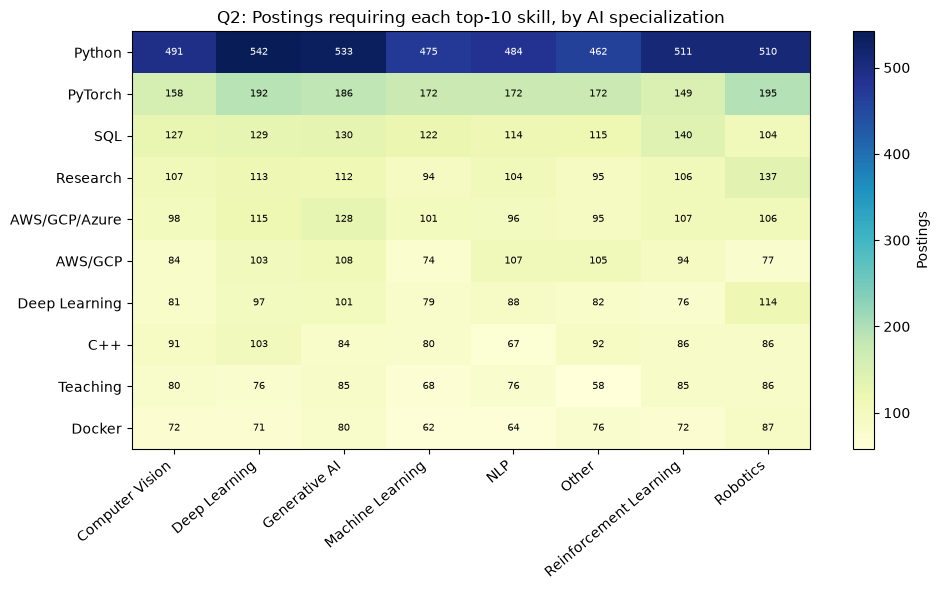

In [20]:
h = r2.pivot_table(index="skill_name", columns="specialization_name", values="postings_in_specialization", fill_value=0)
h = h.loc[h.sum(axis=1).sort_values(ascending=False).index]
fig, ax = plt.subplots(figsize=(10, 6))
im = ax.imshow(h.values, cmap="YlGnBu", aspect="auto")
ax.set_xticks(range(h.shape[1])); ax.set_xticklabels(h.columns, rotation=40, ha="right")
ax.set_yticks(range(h.shape[0])); ax.set_yticklabels(h.index)
for i in range(h.shape[0]):
    for j in range(h.shape[1]):
        ax.text(j, i, int(h.values[i, j]), ha="center", va="center", fontsize=7,
                color="white" if h.values[i, j] > h.values.max() * 0.6 else "black")
ax.set_title("Q2: Postings requiring each top-10 skill, by AI specialization")
fig.colorbar(im, label="Postings")
plt.tight_layout()
plt.show()

**Interpretation (Q2).** Python is by far the most requested skill, required in 4,008 of the 5,000 postings (about 80%), well ahead of PyTorch (1,396), SQL (981) and Research (868).
The heatmap shows Python is the top skill in every specialization, with between 462 postings (Other) and 542 (Deep Learning). Those gaps mostly reflect how many postings each
specialization has (578 and 668), because Python appears in about 80 to 81% of both. Differences between specializations are therefore small: the same core skills are asked for everywhere,
and the specialization changes the count much less than the skill does. We can notice that `AWS/GCP/Azure` (846) and `AWS/GCP` (752) are counted separately because they are written differently in the source.

## Q3. Which 10 job titles have the highest average salary in USD (among titles with at least 20 records)?

In [21]:
Q3 = """
SELECT t.job_title, COUNT(*) AS postings,
       ROUND(AVG(f.salary_usd), 0) AS avg_salary_usd
FROM gold.fact_job_posting f JOIN gold.dim_job_title t USING (title_key)
GROUP BY t.job_title
HAVING COUNT(*) >= 20
ORDER BY avg_salary_usd DESC, t.job_title
LIMIT 10"""
r3 = sql(Q3)
display(r3)
display(sql("""SELECT COUNT(*) AS titles, MIN(n) AS fewest_postings, ROUND(MIN(a), 0) AS lowest_avg_salary FROM
               (SELECT t.job_title, COUNT(*) n, AVG(f.salary_usd) a
                FROM gold.fact_job_posting f JOIN gold.dim_job_title t USING (title_key) GROUP BY 1)"""))

,job_title,postings,avg_salary_usd
0,Lead Data Scientist,129,171076.0
1,Robotics Engineer,148,169702.0
2,AI Solutions Architect,155,168143.0
3,Generative AI Engineer,113,166494.0
4,AI Policy Advisor,138,165425.0
5,AI Software Engineer,144,165359.0
6,Research Engineer,133,164324.0
7,AI Trainer,158,163639.0
8,Data Scientist,106,163436.0
9,AI Infrastructure Engineer,160,162600.0


,titles,fewest_postings,lowest_avg_salary
0,36,106,144976.0


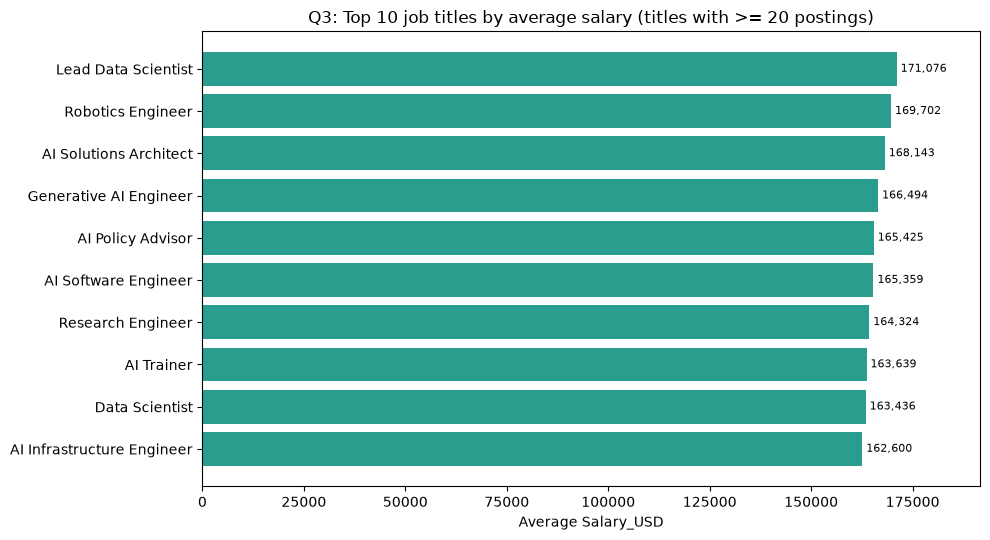

In [22]:
r = r3.iloc[::-1]
fig, ax = plt.subplots(figsize=(10, 5.5))
ax.barh(r["job_title"], r["avg_salary_usd"], color="#2a9d8f")
for y, v in enumerate(r["avg_salary_usd"]):
    ax.text(v, y, f" {v:,.0f}", va="center", fontsize=8)
ax.set_xlabel("Average Salary_USD"); ax.set_xlim(0, r["avg_salary_usd"].max() * 1.12)
ax.set_title("Q3: Top 10 job titles by average salary (titles with >= 20 postings)")
plt.tight_layout();
plt.show()

**Interpretation (Q3).** Lead Data Scientist has the highest average salary ($171,076, 129 postings), followed by Robotics Engineer ($169,702) and AI Solutions Architect ($168,143).
The top ten are close together: the gap between first and tenth (AI Infrastructure Engineer, $162,600) is only about $8,500 (5%).
Across all 36 titles the lowest average is about $144,976, so the spread from best to worst title is roughly $26,000 (18%). Every title has at least 106 postings, so the
20-posting minimum removed nothing and none of these averages rests on a tiny sample.

## Q4. How does the average remote-work percentage differ across AI specializations?

In [23]:
Q4 = """
SELECT s.specialization_name, COUNT(*) AS postings,
       ROUND(AVG(f.remote_work_pct), 1) AS avg_remote_work_pct
FROM gold.fact_job_posting f JOIN gold.dim_specialization s USING (specialization_key)
GROUP BY s.specialization_name
ORDER BY avg_remote_work_pct DESC, s.specialization_name"""
r4 = sql(Q4)
display(r4)
display(sql("SELECT ROUND(AVG(remote_work_pct), 1) AS overall_avg_remote_pct FROM gold.fact_job_posting"))

,specialization_name,postings,avg_remote_work_pct
0,Generative AI,652,59.8
1,Other,578,58.2
2,Reinforcement Learning,634,58.2
3,Machine Learning,613,57.9
4,Deep Learning,668,57.8
5,Computer Vision,623,57.7
6,NLP,589,57.0
7,Robotics,643,55.3


,overall_avg_remote_pct
0,57.7


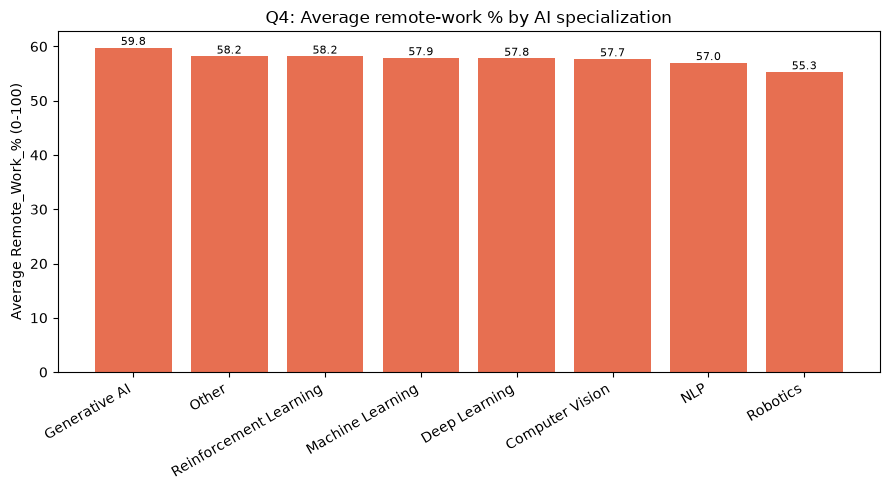

In [24]:
fig, ax = plt.subplots(figsize=(9, 5))
ax.bar(r4["specialization_name"], r4["avg_remote_work_pct"], color="#e76f51")
for x, v in enumerate(r4["avg_remote_work_pct"]):
    ax.text(x, v, f"{v:.1f}", ha="center", va="bottom", fontsize=8)
ax.set_ylabel("Average Remote_Work_% (0-100)")
ax.set_title("Q4: Average remote-work % by AI specialization")
plt.xticks(rotation=30, ha="right");
plt.tight_layout()
plt.show()

**Interpretation (Q4).** Generative AI roles are the most remote-friendly (average 59.8% remote, 652 postings) and Robotics roles the least (55.3%, 643 postings), which is plausible
because robotics work often involves physical hardware. The gap between them is only 4.5 percentage points, and every specialization sits within a few points of the overall average (about 57.7%).
Remote work is therefore common across AI specializations rather than tied to one of them. Because `Remote_Work_%` takes only the values 0, 20, 40, 60, 80 and 100, an average near 58% means a mix of arrangements,
not that postings are typically "58% remote".

In [25]:
from pathlib import Path

results_dir = Path("results")
results_dir.mkdir(parents=True, exist_ok=True)     # creates the folder if it is missing

r1.to_csv(results_dir / "q1_company_openings.csv", index=False)
r2.to_csv(results_dir / "q2_skills_by_specialization.csv", index=False)
r3.to_csv(results_dir / "q3_salary_by_title.csv", index=False)
r4.to_csv(results_dir / "q4_remote_by_specialization.csv", index=False)

print("Saved:", sorted(p.name for p in results_dir.glob("*.csv")))

Saved: ['q1_company_openings.csv', 'q2_skills_by_specialization.csv', 'q3_salary_by_title.csv', 'q4_remote_by_specialization.csv']


# Task 7 - Reflect on the design

The most important design decision was keeping the Gold fact table at one row per job posting and connecting skills through a bridge table. `Skills_Required` stores several skills in one text field, so Question 2 could not be answered correctly until it was split into one row per job and skill. The bridge keeps the grain at one row per `Job_ID`, so salary and openings are never double counted.

The main data-quality challenge was the dates. `Posted_Date` runs from 2026 to 2039, 4,760 of the 5,000 rows are posted after `Record_Created`, and `Record_Created` has only one value, so neither could be a real watermark. I simulated the daily extracts on `Posted_Date` and reported the date problem in the quality report instead of deleting rows.

Cleaning increased trust because every row is accounted for: Bronze 5,000 equals Silver 5,000 plus 0 quarantined, `Job_ID` is unique, the critical columns have no nulls, and Gold has no orphan keys. The seven rules are written down and any failing row would go to quarantine with its reason, so an empty quarantine is a result, not a missing check.

One limitation is that differences between groups are small, and the pay period of `Salary_USD` is not stated, so the results describe this dataset and not the wider labour market.

If the dataset were refreshed regularly, I would add a reliable change date so `QUALIFY` and `MERGE` can pick the latest version of a posting, and keep a history of quality reports so drift is visible.